In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
DATASET_DIR = r"archive-3"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

class_names = sorted([
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
])

print("Emotion classes:")
for i, emotion in enumerate(class_names):
    print(i, ":", emotion)

print("\nNumber of classes:", len(class_names))



Emotion classes:
0 : angry
1 : disgust
2 : fear
3 : happy
4 : neutral
5 : sad
6 : surprise

Number of classes: 7


In [4]:
def count_images(directory):
    counts = {}

    for emotion in class_names:
        emotion_path = os.path.join(directory, emotion)

        if os.path.exists(emotion_path):
            count = len([
                f for f in os.listdir(emotion_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ])

            counts[emotion] = count

    return counts


train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)

print("Training images:")
for emotion, count in train_counts.items():
    print(f"{emotion}: {count}")

print("\nTesting images:")
for emotion, count in test_counts.items():
    print(f"{emotion}: {count}")

Training images:
angry: 3995
disgust: 436
fear: 4097
happy: 7215
neutral: 4965
sad: 4830
surprise: 3171

Testing images:
angry: 958
disgust: 111
fear: 1024
happy: 1774
neutral: 1233
sad: 1247
surprise: 831


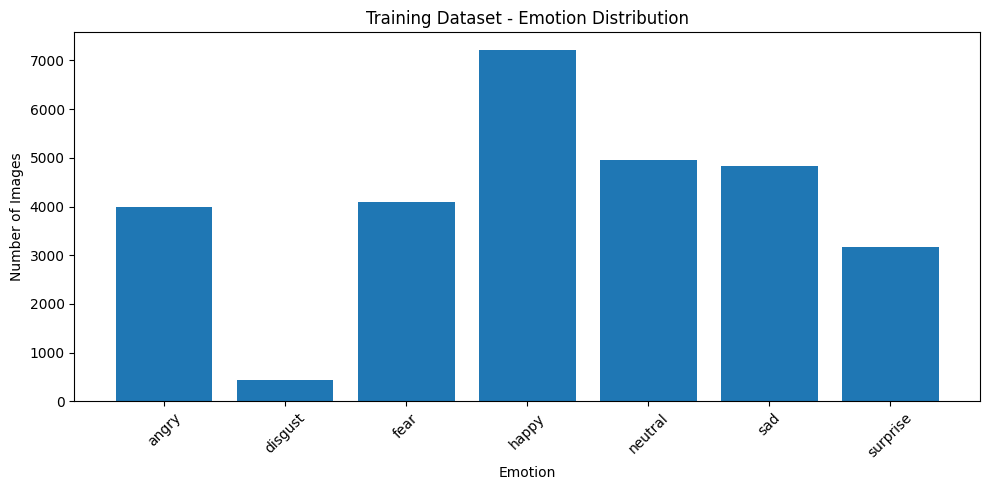

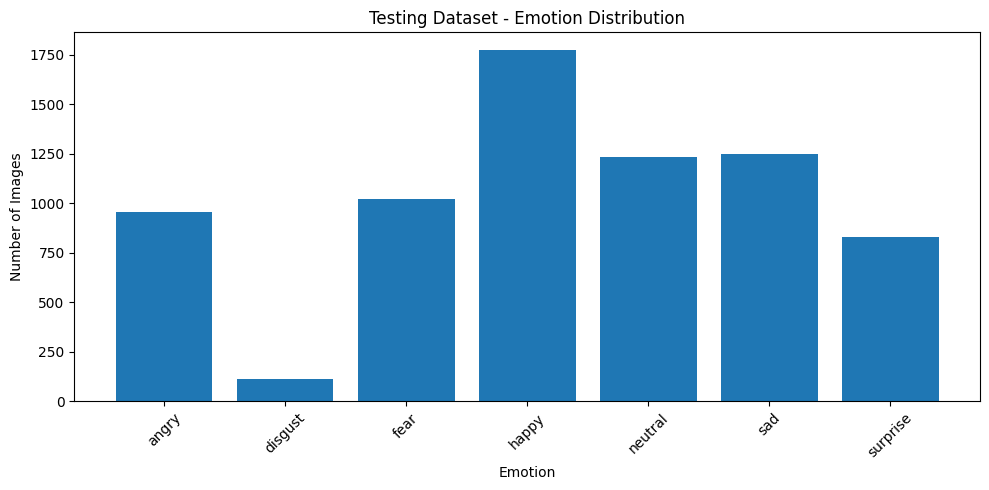

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(train_counts.keys(), train_counts.values())

plt.title("Training Dataset - Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.bar(test_counts.keys(), test_counts.values())

plt.title("Testing Dataset - Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## IMAGE PREPROCESSING

In [6]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    
    transforms.ToTensor(),
    
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    
    transforms.ToTensor(),
    
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [7]:
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)
print("Classes:", train_dataset.classes)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Training samples: 28709
Testing samples: 7178


In [8]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

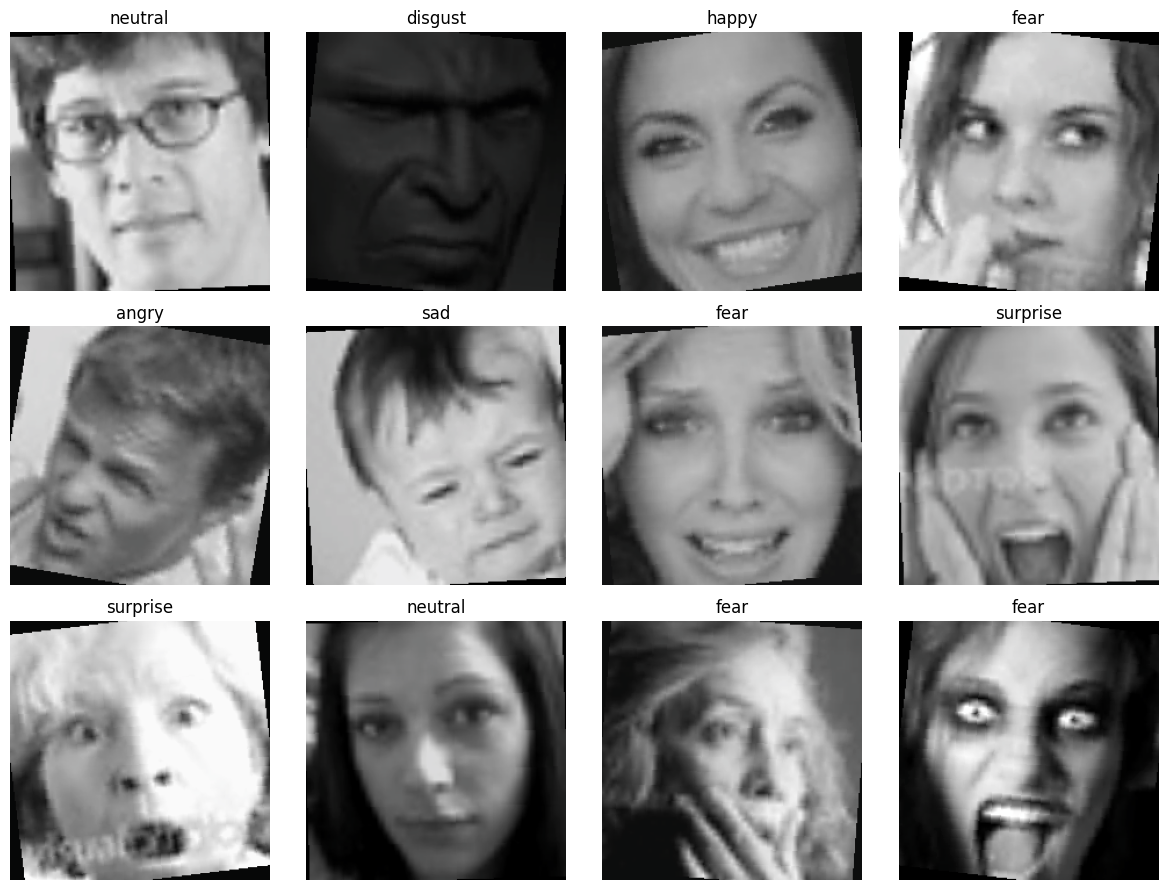

In [9]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    if i < len(images):
        image = images[i].permute(1, 2, 0).numpy()

        # Undo normalization
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])

        image = std * image + mean
        image = np.clip(image, 0, 1)

        ax.imshow(image)
        ax.set_title(class_names[labels[i]])
        ax.axis("off")

plt.tight_layout()
plt.show()

## 12. Build the CNN model

In [10]:
class DeepFER_CNN(nn.Module):

    def __init__(self, num_classes=7):

        super(DeepFER_CNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Sequential(

            nn.AdaptiveAvgPool2d((1, 1)),

            nn.Flatten(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

In [11]:
model = DeepFER_CNN(
    num_classes=len(class_names)
)

model = model.to(device)

print(model)

DeepFER_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.25, inp

## Loss function and optimizer

In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [13]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [14]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [17]:
EPOCHS = 20

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

best_accuracy = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    test_loss, test_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    scheduler.step(test_loss)

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

    if test_acc > best_accuracy:

        best_accuracy = test_acc

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

        print("Best model saved!")

Epoch [1/20] | Train Loss: 1.3543 | Train Acc: 48.63% | Test Loss: 1.3171 | Test Acc: 49.58%
Best model saved!
Epoch [2/20] | Train Loss: 1.3413 | Train Acc: 49.05% | Test Loss: 1.2762 | Test Acc: 51.67%
Best model saved!
Epoch [3/20] | Train Loss: 1.3407 | Train Acc: 49.12% | Test Loss: 1.3379 | Test Acc: 48.29%
Epoch [4/20] | Train Loss: 1.3258 | Train Acc: 49.61% | Test Loss: 1.2593 | Test Acc: 51.46%
Epoch [5/20] | Train Loss: 1.2791 | Train Acc: 52.04% | Test Loss: 1.2876 | Test Acc: 50.72%
Epoch [6/20] | Train Loss: 1.2736 | Train Acc: 51.85% | Test Loss: 1.2155 | Test Acc: 53.80%
Best model saved!
Epoch [7/20] | Train Loss: 1.2623 | Train Acc: 52.34% | Test Loss: 1.1817 | Test Acc: 54.68%
Best model saved!
Epoch [8/20] | Train Loss: 1.2533 | Train Acc: 52.75% | Test Loss: 1.1847 | Test Acc: 54.50%
Epoch [9/20] | Train Loss: 1.2460 | Train Acc: 52.82% | Test Loss: 1.1712 | Test Acc: 54.78%
Best model saved!
Epoch [10/20] | Train Loss: 1.2424 | Train Acc: 53.15% | Test Loss: 1.196

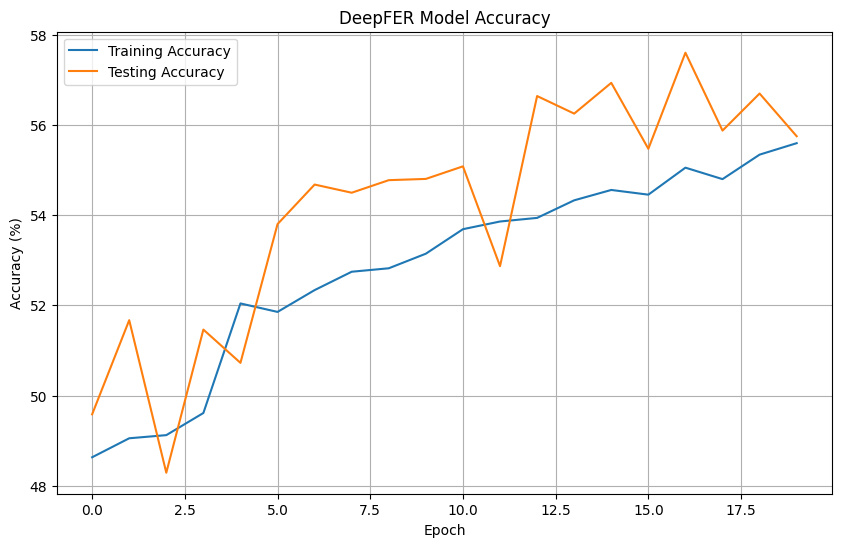

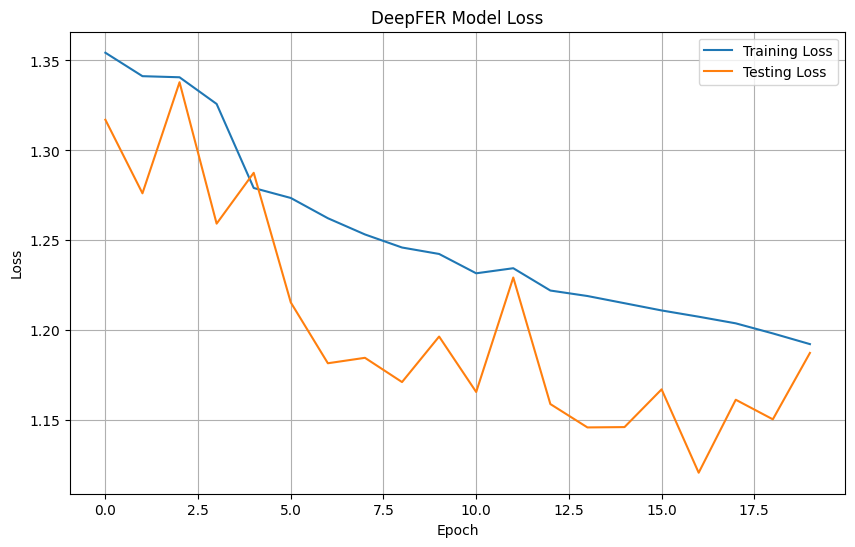

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    test_accuracies,
    label="Testing Accuracy"
)

plt.title("DeepFER Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid()

plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    test_losses,
    label="Testing Loss"
)

plt.title("DeepFER Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

Best Test Accuracy: 57.61%
Final Test Accuracy: 57.60657564781276

Classification Report:

              precision    recall  f1-score   support

       angry       0.49      0.45      0.47       958
     disgust       0.00      0.00      0.00       111
        fear       0.43      0.13      0.21      1024
       happy       0.73      0.85      0.78      1774
     neutral       0.52      0.64      0.57      1233
         sad       0.43      0.51      0.47      1247
    surprise       0.70      0.75      0.72       831

    accuracy                           0.58      7178
   macro avg       0.47      0.48      0.46      7178
weighted avg       0.55      0.58      0.55      7178



C:\Users\Madhu\anaconda3\envs\deep-fake\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Madhu\anaconda3\envs\deep-fake\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Madhu\anaconda3\envs\deep-fake\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


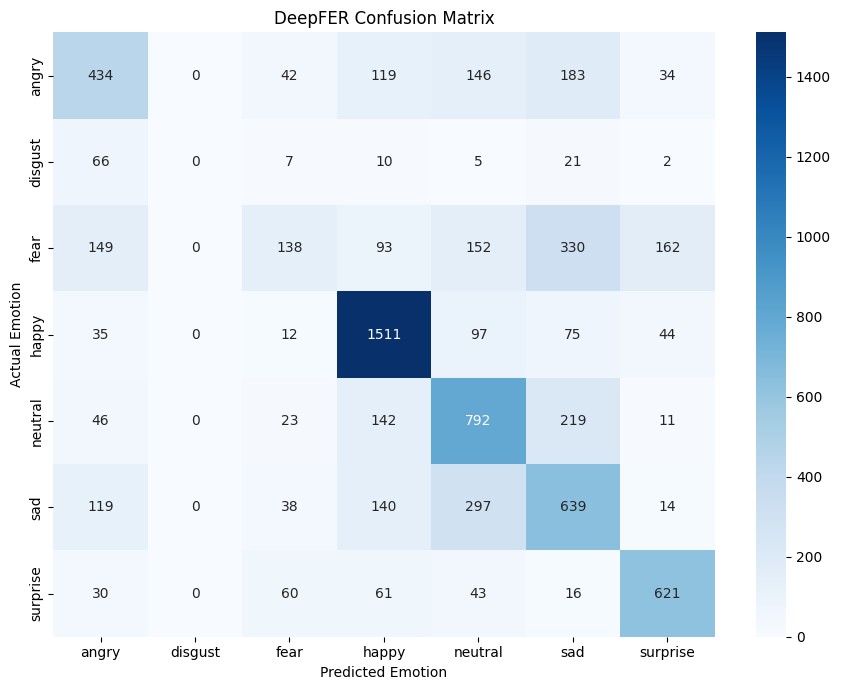

In [20]:
model.load_state_dict(
    torch.load(
        "best_model.pth",
        map_location=device
    )
)

model = model.to(device)

print(
    f"Best Test Accuracy: {best_accuracy:.2f}%"
)

test_loss, test_acc, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion
)

print("Final Test Accuracy:", test_acc)

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("DeepFER Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
def predict_emotion(image_path, model):

    model.eval()

    image = Image.open(image_path).convert("RGB")

    image_tensor = test_transform(image)

    image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    with torch.no_grad():

        output = model(image_tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            1
        )

    emotion = class_names[predicted.item()]

    confidence = confidence.item() * 100

    return emotion, confidence
    
image_path =r"C:\Users\Madhu\Desktop\Screenshot 2026-08-06 201113.png"
 #r"C:\Users\Madhu\Desktop\Screenshot 2026-08-06 200906.png"

emotion, confidence = predict_emotion(
    image_path,
    model
)

print("Predicted Emotion:", emotion)
print("Confidence:", f"{confidence:.2f}%")

Predicted Emotion: happy
Confidence: 80.87%


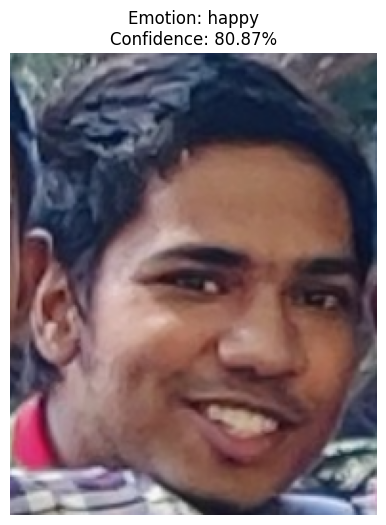

In [24]:
image = Image.open(image_path)

plt.figure(figsize=(6, 6))

plt.imshow(image)
plt.axis("off")

plt.title(
    f"Emotion: {emotion}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

In [25]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMG_SIZE
}

torch.save(
    checkpoint,
    "DeepFER_model.pth"
)

print("Model saved successfully!")

Model saved successfully!
